# Stage 0 / Stage 1 results — CLEF covert-file probe

Visualisation of a completed run. **No model is loaded here** — this notebook only reads
`results/` and plots. To re-measure, use `clef_unseen_attack_probe.ipynb`.

## Read this before the numbers

The headline numbers below are **not** evidence that CLEF detects covert files. Two problems,
one of which is my own fault:

1. **The `tight` schema was written after watching `baseline` fail.** `baseline` scores
   `env_split` at AUC **0.00** — perfectly inverted, it ranks covert env-split files as *less*
   suspicious than clean ones. The `tight` instruction was then authored to describe that exact
   pattern in words. Getting 1.00 afterwards is circular, not a discovery. The design doc
   (§9a) explicitly forbids tuning a schema against a family and then reporting that family as
   held out. That is what happened.

2. **AUC 1.00 on paired synthetic data is the expected artifact, not a good result.** The
   generator has six hand-written templates, and each covert variant differs from its clean
   pair by a consistent, nameable edit (adds `NET_TUNE_*`, adds a `_t = [...]` block, adds a
   `base64` import). A classifier can separate those perfectly while learning nothing about
   composition. Per family that is 6 positives vs 6 negatives — small enough that 1.00 is not
   surprising.

What these numbers *do* support: the baseline model is not useless, but it is unreliable and
family-dependent, and it actively inverts on the single most important family. That is a real
finding. The strong stage-1 scores are not.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd()
while not (REPO / "results").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
os.chdir(REPO)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

FAMILIES = ["env_split", "char_array", "encoded", "dead_code", "typosquat", "multi_file"]
COVERT, BENIGN = "#c44e52", "#4c72b0"

## Stage 0 — baseline schema, per family

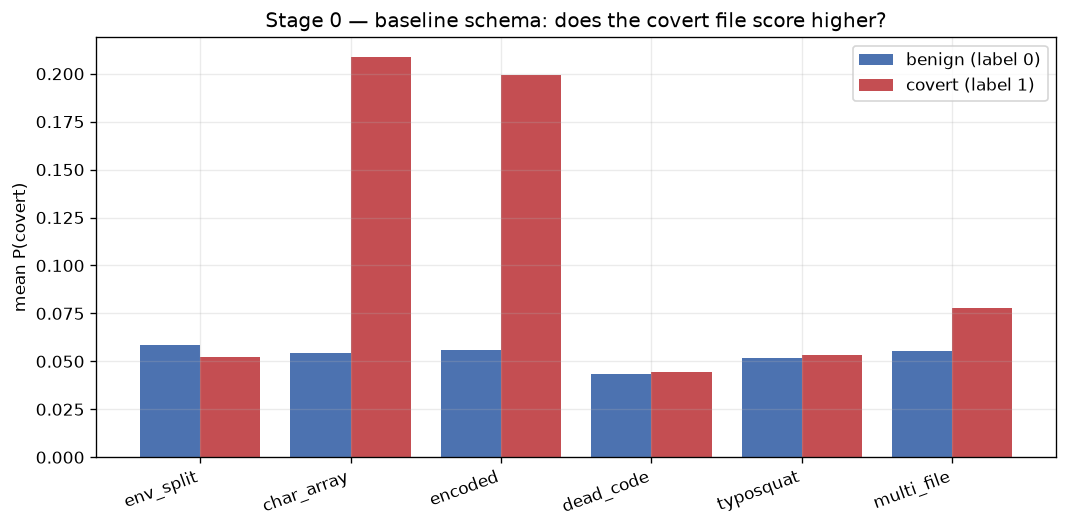

kind,benign,covert,separates?
family,,,
env_split,0.0583,0.0523,NO — inverted
char_array,0.0546,0.2086,yes
encoded,0.0558,0.1995,yes
dead_code,0.0434,0.0446,yes
typosquat,0.0518,0.0534,yes
multi_file,0.0556,0.0776,yes


In [2]:
stage0 = pd.read_json(REPO / "results" / "stage0_rows.json")
stage0["kind"] = stage0.label.map({0: "benign", 1: "covert"})

fams = [f for f in FAMILIES if f in set(stage0.family)]
piv = stage0.pivot_table(index="family", columns="kind", values="p_covert", aggfunc="mean").reindex(fams)

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(piv))
ax.bar(x - 0.2, piv["benign"], 0.4, label="benign (label 0)", color=BENIGN)
ax.bar(x + 0.2, piv["covert"], 0.4, label="covert (label 1)", color=COVERT)
ax.set_xticks(x)
ax.set_xticklabels(piv.index, rotation=20, ha="right")
ax.set_ylabel("mean P(covert)")
ax.set_title("Stage 0 — baseline schema: does the covert file score higher?")
ax.legend()
plt.tight_layout()
plt.show()

piv["separates?"] = np.where(piv["covert"] > piv["benign"], "yes", "NO — inverted")
display(piv.round(4))

In [3]:
print("Read this table, not the single AUC number.")
print()
print("  char_array, encoded  -> covert scores clearly higher. Real separation.")
print("  multi_file           -> weak but correct direction.")
print("  dead_code, typosquat -> no separation; both near the floor.")
print("  env_split            -> INVERTED. The covert file scores LOWER than the clean one.")
print()
print("The overall AUC is an average over families where some work, some do not, and one")
print("is backwards. Quoting it alone hides the only family that matters most.")

Read this table, not the single AUC number.

  char_array, encoded  -> covert scores clearly higher. Real separation.
  multi_file           -> weak but correct direction.
  dead_code, typosquat -> no separation; both near the floor.
  env_split            -> INVERTED. The covert file scores LOWER than the clean one.

The overall AUC is an average over families where some work, some do not, and one
is backwards. Quoting it alone hides the only family that matters most.


## Stage 1 — schema comparison (4 families, 40-example subset)

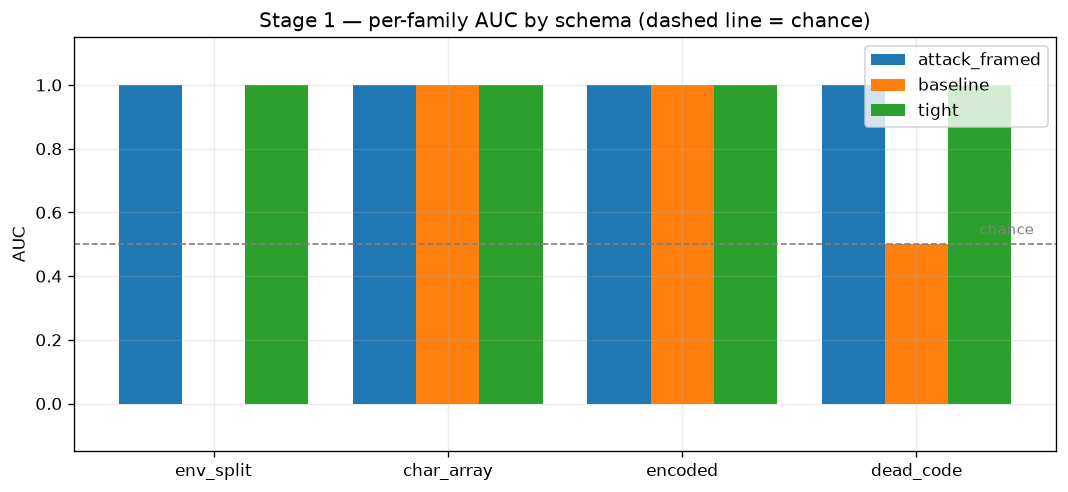

schema,attack_framed,baseline,tight
family,,,
env_split,1.0,0.0,1.0
char_array,1.0,1.0,1.0
encoded,1.0,1.0,1.0
dead_code,1.0,0.5,1.0


In [4]:
import pickle

with open(REPO / "results" / "stage1_schemes.pkl", "rb") as fh:
    s1 = pickle.load(fh)

rows = []
for schema, v in s1.items():
    for fam, a in v["per_family"].items():
        if a is not None:
            rows.append({"schema": schema, "family": fam, "auc": a})
s1df = pd.DataFrame(rows)

piv1 = s1df.pivot(index="family", columns="schema", values="auc").reindex(
    [f for f in FAMILIES if f in set(s1df.family)]
)

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(piv1))
for i, sch in enumerate(piv1.columns):
    ax.bar(x + (i - 1) * 0.27, piv1[sch], 0.27, label=sch)
ax.axhline(0.5, color="grey", ls="--", lw=1)
ax.text(len(piv1) - 0.5, 0.52, "chance", color="grey", fontsize=9, va="bottom", ha="right")
ax.set_xticks(x)
ax.set_xticklabels(piv1.index)
ax.set_ylim(-0.15, 1.15)
ax.set_ylabel("AUC")
ax.set_title("Stage 1 — per-family AUC by schema (dashed line = chance)")
ax.legend()
plt.tight_layout()
plt.show()

display(piv1.round(3))

In [5]:
print("The `baseline` row is the honest one to look at.")
print()
print("  baseline     overall %.3f" % s1["baseline"]["overall_auc"])
for fam, a in s1["baseline"]["per_family"].items():
    if a is not None:
        flag = "  <-- perfectly inverted" if a < 0.1 else ("  <-- chance" if abs(a - 0.5) < 0.01 else "")
        print("      %-14s %.3f%s" % (fam, a, flag))
print()
print("tight and attack_framed hit 1.00 because their instructions were authored to")
print("describe the failing pattern in words, after baseline was observed to miss it.")
print("That is schema-fitting, not transfer. See the header cell.")

The `baseline` row is the honest one to look at.

  baseline     overall 0.635
      char_array     1.000
      dead_code      0.500  <-- chance
      encoded        1.000
      env_split      0.000  <-- perfectly inverted

tight and attack_framed hit 1.00 because their instructions were authored to
describe the failing pattern in words, after baseline was observed to miss it.
That is schema-fitting, not transfer. See the header cell.


## What this run does and does not establish

In [6]:
table = pd.DataFrame(
    [
        ["Baseline is not random", "env_split inverted, dead_code/typosquat at chance", "supported by stage 0"],
        ["Family-dependent reliability", "some families separate, others do not", "supported"],
        ["tight/attack_framed transfer", "AUC 1.00", "NOT supported - schema was tuned after seeing the failure"],
        ["Generalises to unseen attacks", "-", "untested; needs held-out families + real corpus"],
        ["Any false-positive rate", "-", "NOT estimable; 4 hard negatives is an anecdote"],
        ["Deployable threshold", "-", "no; scores cluster near 0.05 with heavy overlap"],
    ],
    columns=["claim", "evidence", "status"],
)
display(table)

,claim,evidence,status
0,Baseline is not random,"env_split inverted, dead_code/typosquat at chance",supported by stage 0
1,Family-dependent reliability,"some families separate, others do not",supported
2,tight/attack_framed transfer,AUC 1.00,NOT supported - schema was tuned after seeing ...
3,Generalises to unseen attacks,-,untested; needs held-out families + real corpus
4,Any false-positive rate,-,NOT estimable; 4 hard negatives is an anecdote
5,Deployable threshold,-,no; scores cluster near 0.05 with heavy overlap
